# BLUESKY REPORT

**Name:** Kevin Ku

**Date:** 10/19/26

**Report:** API Data report 


## Question

My question does does bluesky get more followers or likes on post?

## Hypothesis

I think Bluesky with more followers will have more likes per post.

## Theoretical

If a account recieve more followers it get more engagement.

## Statistical Application

I am going to compare the followers with the average number of likes per posts.

## Variables

* Number of followers
* Averge likes per post





## API Endpoints

## Endpoint 1: app.bsky.actor.getProfile

I will use this to get profile information, follower counts, following counts, post counts

## Endpoint 2: app.bsky.feed.getAuthorFeed

I will use this to provide post that associated with a bluesky account. include enggement metrics.


In [17]:
import requests
import pandas as pd
import matplotlib.pyplot as plt








I imported requests to get data from Bluesky API. Panda is used to organize he tables, and I use matplotlib to create a graph. 

In [18]:
accounts=["bsky.app","nytimes.com","theguardian.com"]

profile_data=[]

for account in accounts:

    url="https://public.api.bsky.app/xrpc/app.bsky.actor.getProfile"

    params={

        "actor": account
    }

    response= requests.get(
        url, 
        params=params,
        timeout=15
    )

    response.raise_for_status()
    data=response.json()

    profile_data.append({

        "account": data["did"],
        "name":data.get("displayName",account),
        "followers": data.get("followersCount",0),
        "total_posts": data.get("postsCount",0)
    })

profiles_df=pd.DataFrame(profile_data)

display(profiles_df)


,account,name,followers,total_posts
0,did:plc:z72i7hdynmk6r22z27h6tvur,Bluesky,35313141,883
1,did:plc:eclio37ymobqex2ncko63h4r,The New York Times,1352530,44507
2,did:plc:vovinwhtulbsx4mwfw26r5ni,The Guardian,794302,63682


I use the getProfile API endpoint to collect information from three Blusky. I got the accounts name, followers, and total post. 

In [19]:

post_data=[]

for account in accounts:

    url="https://public.api.bsky.app/xrpc/app.bsky.feed.getAuthorFeed"

    params={

        "actor": account,
        "limit": 50,
        "filter": "posts_no_replies"
        
    }

    response= requests.get(
        url, 
        params=params,
        timeout=15
    )

    response.raise_for_status()
    data = response.json()

    for item in data.get("feed",[]):
        if item.get("reason",{}).get("$type")=="app.bsky.feed.defs#reasonRepost":
            continue
    
        post = item["post"]

   

        post_data.append({

            "account": post ["author"]["did"],
            "post_uri": post["uri"],
            "likes": post.get("likeCount",0),
            "reposts": post.get("repostCount",0),
            "replies": post.get("replyCount",0)
        })
    
posts_df=pd.DataFrame(post_data)

display(posts_df)


   

,account,post_uri,likes,reposts,replies
0,did:plc:z72i7hdynmk6r22z27h6tvur,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,903,114,50
1,did:plc:z72i7hdynmk6r22z27h6tvur,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,8947,1733,634
2,did:plc:z72i7hdynmk6r22z27h6tvur,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,1039,115,111
3,did:plc:z72i7hdynmk6r22z27h6tvur,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,1420,202,178
4,did:plc:z72i7hdynmk6r22z27h6tvur,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,2842,350,69
...,...,...,...,...,...
117,did:plc:vovinwhtulbsx4mwfw26r5ni,at://did:plc:vovinwhtulbsx4mwfw26r5ni/app.bsky...,23,5,1
118,did:plc:vovinwhtulbsx4mwfw26r5ni,at://did:plc:vovinwhtulbsx4mwfw26r5ni/app.bsky...,211,87,0
119,did:plc:vovinwhtulbsx4mwfw26r5ni,at://did:plc:vovinwhtulbsx4mwfw26r5ni/app.bsky...,71,26,1
120,did:plc:vovinwhtulbsx4mwfw26r5ni,at://did:plc:vovinwhtulbsx4mwfw26r5ni/app.bsky...,127,62,11


I use the getAuthorFeed API endpoint to get three Bluesky accounts. I got the account name, reposts, and replied. 

In [20]:

final_df = pd.merge(
    posts_df, 
    profiles_df,
    on="account", 
    how="left"
)

display(final_df)

,account,post_uri,likes,reposts,replies,name,followers,total_posts
0,did:plc:z72i7hdynmk6r22z27h6tvur,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,903,114,50,Bluesky,35313141,883
1,did:plc:z72i7hdynmk6r22z27h6tvur,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,8947,1733,634,Bluesky,35313141,883
2,did:plc:z72i7hdynmk6r22z27h6tvur,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,1039,115,111,Bluesky,35313141,883
3,did:plc:z72i7hdynmk6r22z27h6tvur,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,1420,202,178,Bluesky,35313141,883
4,did:plc:z72i7hdynmk6r22z27h6tvur,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,2842,350,69,Bluesky,35313141,883
...,...,...,...,...,...,...,...,...
117,did:plc:vovinwhtulbsx4mwfw26r5ni,at://did:plc:vovinwhtulbsx4mwfw26r5ni/app.bsky...,23,5,1,The Guardian,794302,63682
118,did:plc:vovinwhtulbsx4mwfw26r5ni,at://did:plc:vovinwhtulbsx4mwfw26r5ni/app.bsky...,211,87,0,The Guardian,794302,63682
119,did:plc:vovinwhtulbsx4mwfw26r5ni,at://did:plc:vovinwhtulbsx4mwfw26r5ni/app.bsky...,71,26,1,The Guardian,794302,63682
120,did:plc:vovinwhtulbsx4mwfw26r5ni,at://did:plc:vovinwhtulbsx4mwfw26r5ni/app.bsky...,127,62,11,The Guardian,794302,63682


I use pd.merge() to combine the post data and profile data into one DataFrame. I matched the tables by using the account identifier so I could compare followers with post likes, repost, and replies.

In [21]:
final_df=final_df.drop_duplicates(subset=["post_uri"])

final_df=final_df.dropna(subset=["followers","likes"])

final_df=final_df.sort_values(by="likes", ascending=False)

display(final_df)





,account,post_uri,likes,reposts,replies,name,followers,total_posts
18,did:plc:z72i7hdynmk6r22z27h6tvur,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,19077,2734,687,Bluesky,35313141,883
15,did:plc:z72i7hdynmk6r22z27h6tvur,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,9628,3354,344,Bluesky,35313141,883
19,did:plc:z72i7hdynmk6r22z27h6tvur,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,9600,2390,493,Bluesky,35313141,883
1,did:plc:z72i7hdynmk6r22z27h6tvur,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,8947,1733,634,Bluesky,35313141,883
5,did:plc:z72i7hdynmk6r22z27h6tvur,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,7639,410,234,Bluesky,35313141,883
...,...,...,...,...,...,...,...,...
73,did:plc:vovinwhtulbsx4mwfw26r5ni,at://did:plc:vovinwhtulbsx4mwfw26r5ni/app.bsky...,4,0,0,The Guardian,794302,63682
108,did:plc:vovinwhtulbsx4mwfw26r5ni,at://did:plc:vovinwhtulbsx4mwfw26r5ni/app.bsky...,4,0,0,The Guardian,794302,63682
98,did:plc:vovinwhtulbsx4mwfw26r5ni,at://did:plc:vovinwhtulbsx4mwfw26r5ni/app.bsky...,4,0,2,The Guardian,794302,63682
112,did:plc:vovinwhtulbsx4mwfw26r5ni,at://did:plc:vovinwhtulbsx4mwfw26r5ni/app.bsky...,3,0,0,The Guardian,794302,63682


I use drop_duplicates() to remove repeated post adn dropa() to remove rows from missing follower or like information. I sort the post from most like to less like.

In [22]:
summary_df=(final_df.groupby(
    ["account","name","followers"],
    as_index=False

    )

    .agg(

        average_likes=("likes", "mean"),
        posts_collected=("post_uri","count")

        )  
    
    )

summary_df= summary_df.sort_values(
        by="followers",
        ascending=False

    )

display(summary_df)


,account,name,followers,average_likes,posts_collected
2,did:plc:z72i7hdynmk6r22z27h6tvur,Bluesky,35313141,4125.160000,25
0,did:plc:eclio37ymobqex2ncko63h4r,The New York Times,1352530,66.957447,47
1,did:plc:vovinwhtulbsx4mwfw26r5ni,The Guardian,794302,47.900000,50


I use groupby() to group the post by account. I caculated the average likes per post and counted how many post are there.

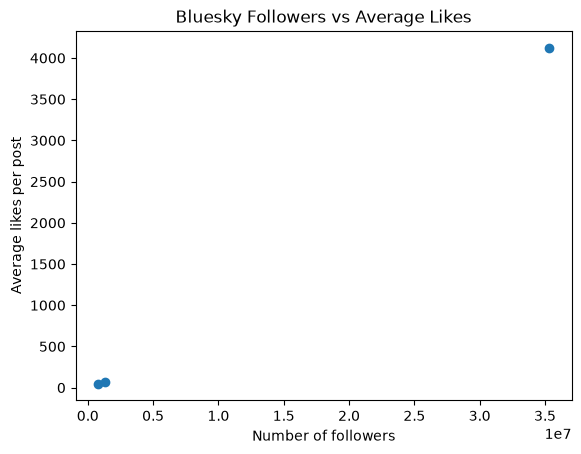

In [23]:
plt.scatter(
    
    summary_df["followers"],
    summary_df["average_likes"]

)

plt.xlabel("Number of followers")
plt.ylabel("Average likes per post")
plt.title("Bluesky Followers vs Average Likes")

plt.show()

I create  agraph to compare the number of follower with average likes per post. The X axis shows followers, and the Y axis shows averege likes. 

## Conclusion

The conclusion about my bluesky API report is that I wanted to find out if accounts wit more followers recieve more likes on their post. I collected data from three bluesky account: bluesky, The New York time, and The Gurardian. 

According to my data Bluesky has the most followers with 35312651 and the highest average like per post with 4114.400000. The New York time has 	1352525 followers and average like per post is 75.244898. The Gurdian had 794,295 followers and averaged 47.88 likes in my sample.

Thefore my result support my hypothesis because it shows the account with more followers higher average likes in my sample.


## Limitation

The limitation of my research is that I only collected data from three bluesky accounts. This mean my result does not represent all bluesky accounts

Also the mumber of followers and like can change over time. Older post may have more likes than newer post.

## Future research

I will collect more data on Bluesky account to compare posts publish the same time.

